# Exercise 1: CNN-based Classification

Please follow the instructions carefully to successfully complete this exercise. Before diving in, please fill out the following markdown cell with your group information.

**Group No.**

*   Student 1 - Name and student ID
*   Student 2 - Name and student ID



## General imports

In [8]:
from PIL import Image
!pip install -q medmnist scikit-learn pandas tqdm matplotlib

In [40]:
import hashlib
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.transforms as T
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Dataset, Subset
from tqdm.auto import tqdm
from pprint import pprint
import random

## 0. Setup your personal seed  (1 Point)

In [62]:
# Enter your student ID or email to generate a reproducible personal seed.
SEED_BASE = "n12631892;n52002647"
if SEED_BASE == "REPLACE_WITH_YOUR_STUDENT_IDS":
    raise NotImplementedError("Enter your group number or student IDs.")

def student_seed(student_id: str) -> int:
    h = hashlib.sha256(student_id.strip().lower().encode("utf-8")).hexdigest()
    return int(h, 16) % (2**32)

SEED = student_seed(SEED_BASE)
torch.manual_seed(SEED)
np.random.seed(SEED)

## 1. Loading DermaMNIST dataset  (8 Points)

This notebook uses the newly adjusted DermaMNIST-C dataset described in https://arxiv.org/pdf/2401.14497) which are derived from HAM10000 dermoscopic skin-lesion images of the MedMNIST (https://medmnist.com/) dataset. It consists of the 28x28
images *and* the original HAM10000 metadata: `lesion_id`, `dx` (diagnosis), `age`,
`sex`, `localization`.

Run the following cell to load the DermaMNIST-C dataset.

In [11]:
import urllib.request
ZENODO_BASE = "https://zenodo.org/records/12739457/files"
urllib.request.urlretrieve(f"{ZENODO_BASE}/DermaMNIST-C.csv?download=1", "DermaMNIST-C.csv")
urllib.request.urlretrieve(f"{ZENODO_BASE}/dermamnist_corrected_28.npz?download=1", "dermamnist_corrected_28.npz")

meta = pd.read_csv("DermaMNIST-C.csv")
npz = np.load("dermamnist_corrected_28.npz")
meta.head()

,lesion_id,image_id,dx,dx_type,age,sex,localization,dataset,split
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp,vidir_modern,train
1,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp,vidir_modern,train
2,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp,vidir_modern,train
3,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear,vidir_modern,train
4,HAM_0001466,ISIC_0027850,bkl,histo,75.0,male,ear,vidir_modern,train


**TODO:** Look up what each of the 7 `dx` codes stand for and decide which are
malignant/pre-cancerous and which are benign. Fill in `MALIGNANT_DX` below (the
remaining categories will be treated as benign). Justify your choice in the markdown cell below, write down, in your own words, the clinical reasoning for each of the 7 categories before you commit to the mapping.

**Your answer (diagnosis grouping and clinical justification):**

In [12]:
# Display dx codes
print("Dx codes and counts inherited from HAM10000 metadata")
print(meta["dx"].value_counts().sort_index())

# Display dx code mapping and description [1]
DX_DESCRIPTIONS = {
   "akiec (m)": "Actinic keratoses (Solar Keratoses) and Intraepithelial Carcinoma (Bowen's disease), precancerous/can develop into malignant. Malignant",
    "bcc (m)": "Basal cell carcinoma, doesn't metastasize but grows destructively. Malignant",
    "bkl (b)": "Benign keratosis, generic grouping class, non malignant but can mimic melanomas therefore often biopsied just to be safe. Benign",
    "df (b)": "Dermatofibroma, benign proliferation or inflammatory reaction to minimal trauma. Benign",
    "nv (b)": "Melanocytic nevi, in contrast to melanoma they're usually symmetric. Benign",
    "mel (m)": "Melanoma. Malignant",
    "vasc (b)": "Vascular skin lesion, various born with or acquired usually benign skin changes. Benign"
}

print()
print("Dx descriptions [1]")
pprint(DX_DESCRIPTIONS)
print()


MALIGNANT_DX = {"akiec", "bcc", "mel"}

DX_ORDER = sorted(meta["dx"].unique())
DX_TO_CODE = {d: i for i, d in enumerate(DX_ORDER)}
print("dx order:", DX_ORDER)
print("malignant:", MALIGNANT_DX, " benign:", set(DX_ORDER) - MALIGNANT_DX)
assert len(MALIGNANT_DX) > 0, "fill in MALIGNANT_DX first"

Dx codes and counts inherited from HAM10000 metadata
dx
akiec     327
bcc       514
bkl      1099
df        115
mel      1113
nv       6705
vasc      142
Name: count, dtype: int64

Dx descriptions [1]
{'akiec (m)': 'Actinic keratoses (Solar Keratoses) and Intraepithelial '
              "Carcinoma (Bowen's disease), precancerous/can develop into "
              'malignant. Malignant',
 'bcc (m)': "Basal cell carcinoma, doesn't metastasize but grows "
            'destructively. Malignant',
 'bkl (b)': 'Benign keratosis, generic grouping class, non malignant but can '
            'mimic melanomas therefore often biopsied just to be safe. Benign',
 'df (b)': 'Dermatofibroma, benign proliferation or inflammatory reaction to '
           'minimal trauma. Benign',
 'mel (m)': 'Melanoma. Malignant',
 'nv (b)': "Melanocytic nevi, in contrast to melanoma they're usually "
           'symmetric. Benign',
 'vasc (b)': 'Vascular skin lesion, various born with or acquired usually '
             'b

Run the following cell to gain some basic insights into the dataset.

In [13]:
n_images = len(meta)
n_lesions = meta["lesion_id"].nunique()
multi_image_lesions = (meta.groupby("lesion_id").size() > 1).sum()
print(f"images: {n_images}, unique lesions: {n_lesions}")
print(f"lesions with 2+ images: {multi_image_lesions} ({multi_image_lesions/n_lesions:.1%} of lesions)")

images: 10015, unique lesions: 7470
lesions with 2+ images: 1956 (26.2% of lesions)


## 2. Splitting the data (7 Points)

### Naïve approach

Above we could see that several lesions are represented by multiple images in the dataset. To demonstrate how this can lead to data leakage, we first perform a naïve stratified split using `train_test_split`, and then look at how many lesions appear in both the training and test sets.

In [14]:
naive_train, naive_test = train_test_split(
    meta, test_size=0.2, stratify=meta["dx"], random_state=SEED
)

leaked = set(naive_train.lesion_id).intersection(naive_test.lesion_id)

print(f"naive split: {len(leaked)} appear in BOTH train and test "
      f"({len(leaked)/n_lesions:.1%} of all lesions)")

naive split: 725 appear in BOTH train and test (9.7% of all lesions)


### DermaMNIST-C

The DermaMNIST-C release we downloaded already provides a `split` column, ensuring no data leakage. We'll use it directly, but first, we verify that it is leakage-free before trusting it.

In [15]:
# Verify that no lesion occurs in more than one official split.
splits_of_lesion = meta.groupby("lesion_id")["split"].nunique()

lesions_in_multiple_splits = splits_of_lesion[
   splits_of_lesion > 1
]

assert lesions_in_multiple_splits.empty, (
   "Some lesions occur in multiple splits:\n"
   f"{lesions_in_multiple_splits}"
)

print("Verified: no lesion occurs in more than one split.")

Verified: no lesion occurs in more than one split.


In [75]:
def build_split(split_name):
    metadata = meta[meta["split"] == split_name].reset_index(drop=True)
    images = npz[f"{split_name}_images"]
    assert len(metadata) == len(images)

    # Convert diagnosis codes into binary malignant/benign labels.
    # 1 = malignant, 0 = benign
    dx_bin = metadata["dx"].isin(MALIGNANT_DX).astype(int)

    return {
        "imgs": images.astype(np.float32) / 255.0,
        "dx": metadata["dx"].values,
        "dx_code": metadata["dx"].map(DX_TO_CODE).values.astype(np.int64),
        "dx_bin": dx_bin.to_numpy(),
        "lesion_id": metadata["lesion_id"].values,
    }

splits = {which: build_split(which) for which in ("train", "val", "test")}
for s, d in splits.items():
    n_malig = d["dx_bin"].sum()
    print(f"{s}: n={len(d['dx'])}, malignant={n_malig} ({n_malig/len(d['dx']):.1%})")

train: n=8215, malignant=1742 (21.2%)
val: n=573, malignant=63 (11.0%)
test: n=1227, malignant=149 (12.1%)


## 3. Data visualization (5 Points)

Visualize some samples of the dataset and check whether the images are looking correct. Fill in the missing parts of the function below to show 10 randomly selected images with their corresponding labels.

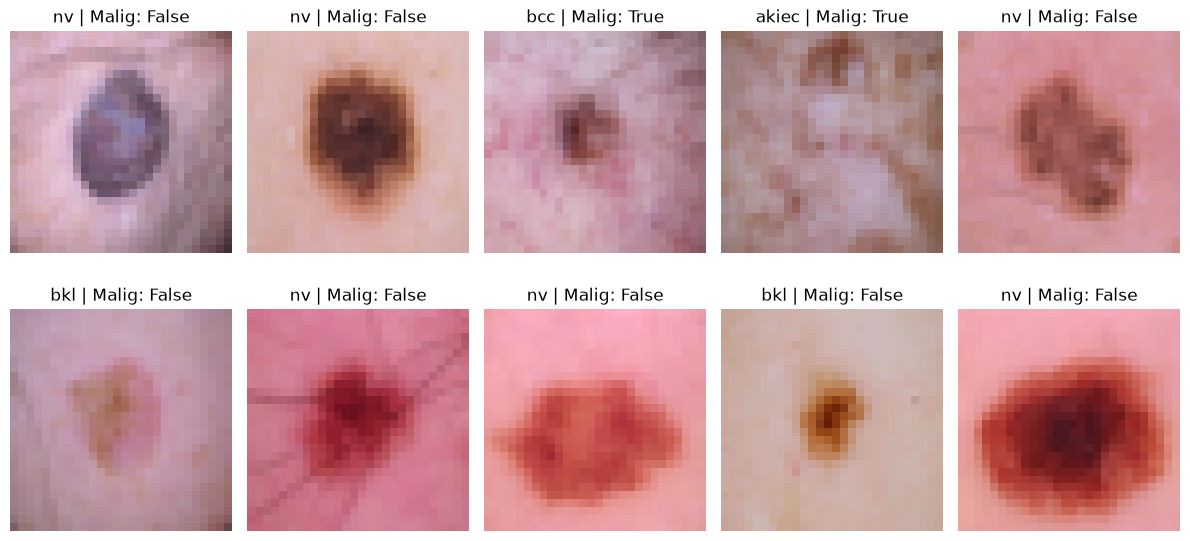

Images are pixelated as they are already downsampled to: 28x28px


In [97]:
def visualize_images(splits, which="train", seed=SEED):
    fig, axes = plt.subplots(2, 5, figsize=(12, 6))

    # Randomly sample 10 image indices to visualize using the seed to get reproducible results.
    rng = np.random.default_rng(seed)
    samples_idx = rng.choice (len(splits[which]["imgs"]), size=10, replace=False)

    for i, idx in enumerate(samples_idx):
        ax = axes[i // 5, i % 5]

        # Select the image at idx and the corresponding labels, then display it.
        image = splits[which]["imgs"][idx]
        dx_label = splits[which]["dx"][idx]
        is_malignant = splits[which]["dx_bin"][idx]

        ax.imshow(image)
        ax.set_title(f"{dx_label} | Malig: {is_malignant.astype(bool)}")
        ax.axis("off")

    plt.tight_layout()
    plt.show()

    height, width = splits["train"]["imgs"][0].shape[:2]
    print("Images are pixelated as they are already downsampled to:", f"{height}x{width}px")

visualize_images(splits, which="train")

## 4. Data augmentation (7 Points)

For the training dataset, we often apply data augmentation techniques to improve the models' generalization ability, robustness to variations in input data, and convergence during training. Define an augmentation pipeline using [torchvision transforms](https://docs.pytorch.org/vision/0.9/transforms.html).
Think about how you should combine the different methods and parameters to meaningfully augment the given dataset during training and change the previously defined function to visualize them.

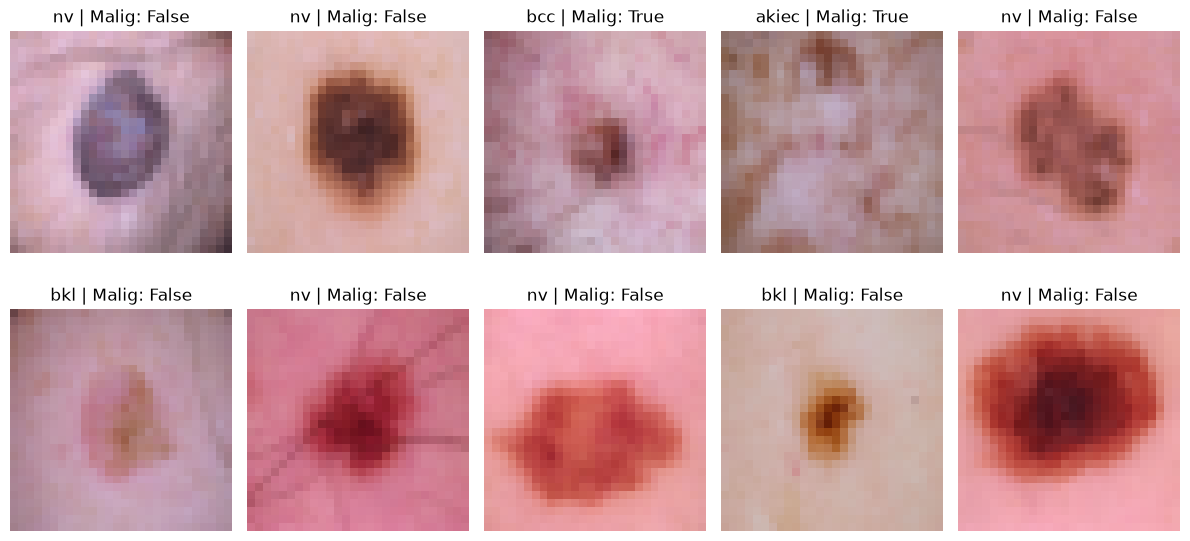

Images are pixelated as they are already downsampled to: 28x28px


In [115]:
# Define a clinically sensible augmentation pipeline.
# Define basic/small augmentation
weak_aug = T.Compose([
    T.RandomVerticalFlip(p=0.5),
    T.RandomHorizontalFlip(p=0.5),
])

# Define strong/agressive augmentation
strong_aug = T.Compose([
    T.RandomHorizontalFlip(p=0.5),
    T.RandomVerticalFlip(p=0.5),
    T.RandomCrop(20),
    T.GaussianBlur(3, sigma=(1, 3)),
    T.RandomPerspective()
])

augment_pipeline = weak_aug

# Extend the visualization function so that it optionally applies transform
def visualize_images(splits, which="train", transform=None, seed=SEED):
    fig, axes = plt.subplots(2, 5, figsize=(12, 6))

    # Randomly sample 10 image indices to visualize using the seed to get reproducible results.
    rng = np.random.default_rng(seed)
    samples_idx = rng.choice(len(splits[which]["imgs"]), size=10, replace=False)

    for i, idx in enumerate(samples_idx):
        ax = axes[i // 5, i % 5]

        # Select the image at idx and the corresponding labels, then display it.
        image = splits[which]["imgs"][idx]
        if transform is not None:
            image = torch.from_numpy(image).permute(2, 0, 1)
            image = transform(image)
            image = image.permute(1, 2, 0).numpy()

        dx_label = splits[which]["dx"][idx]
        is_malignant = splits[which]["dx_bin"][idx]

        ax.imshow(image)
        ax.set_title(f"{dx_label} | Malig: {is_malignant.astype(bool)}")
        ax.axis("off")

    plt.tight_layout()
    plt.show()

    height, width = splits["train"]["imgs"][0].shape[:2]
    print("Images are pixelated as they are already downsampled to:", f"{height}x{width}px")

visualize_images(splits, which="train", transform=augment_pipeline)

## 5. Creating a custom dataset and setting up the dataloader  (10 Points)

To easily feed our data into a Pytorch model, we create a custom dataset. A custom Dataset class must implement three functions: __init__, __len__, and __getitem__. Then, we load that dataset into the DataLoader and can iterate through the dataset as needed.

In [122]:
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEVICE)

class CustomDataset(Dataset):
    def __init__(self, images, labels):
        self.images = images
        self.labels = labels

    def __len__(self):
        # Return the number of samples.
        return len(self.images)

    def __getitem__(self, index):
        image = self.images[index]
        label = self.labels[index]


def split_to_tensors(split_name, label_key):
    """Convert one HWC NumPy split to PyTorch tensors."""
    split = splits[split_name]
    # torch.from_numpy expects writeable array -> make writeable copy
    writeable_imgs=np.array(split["imgs"], copy=True)
    writeable_labels=np.array(split[label_key], copy=True)
    # convert to tensors by changing the order of dimensions
    # numpy: (no_img, height, width, channels) => tensor: (no_img, channels, height, width)
    images = torch.from_numpy(writeable_imgs).permute(0, 3, 1, 2).contiguous()
    labels = torch.from_numpy(writeable_labels)
    return images, labels


def make_loader(dataset, batch_size=64, shuffle=False, seed=SEED):
    # Create seeded generator to be used in the dataloader when meaningful, else set it to None.
    # The seeded generator ensures that the shuffled training set is reproducible via the seed.
    if shuffle:
        generator = torch.Generator()
        generator.manual_seed(seed)
    else:
        generator = None
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle, generator=generator)


# Create consistently configured datasets and loaders for all three splits.
def make_data_bundle(label_key="dx_bin", batch_size=64, seed=SEED):
    # Init empty dictionary
    datasets = {}
    loaders = {}

    for split_name in ("train", "val", "test"):
        images, labels = split_to_tensors(
           split_name,
           label_key,
        )

        datasets[split_name] = CustomDataset(
           images,
           labels,
        )

        # only training set should be shuffled
        loaders[split_name] = make_loader(
           datasets[split_name],
           batch_size=batch_size,
           shuffle=(split_name == "train"),
           seed=seed,
        )
    return datasets, loaders


BATCH_SIZE = 64
binary_datasets, binary_loaders = make_data_bundle("dx_bin", BATCH_SIZE)
train_dataset, val_dataset, test_dataset = (
    binary_datasets["train"], binary_datasets["val"], binary_datasets["test"]
)
train_loader, val_loader, test_loader = (
    binary_loaders["train"], binary_loaders["val"], binary_loaders["test"]
)
x_train, y_train = train_dataset.images, train_dataset.labels
x_val, y_val = val_dataset.images, val_dataset.labels
x_test, y_test = test_dataset.images, test_dataset.labels

device: cpu


## 6. Building a simple CNN architecture (8 Points)

The [torch.nn](https://docs.pytorch.org/docs/2.14/nn.html) namespace provides all the building blocks to build a neural network. As a baseline model, define your own CNN classifier. Think about what layers to include and in what order.

In [120]:
class SmallCNN(nn.Module):
    def __init__(self, input_size, n_channels, n_outputs):
        super().__init__()
        # Define the convolutional feature extractor and classification head.
        ## Convolutional feature extractor

        ## Classification head

    def forward(self, images):
        # TODO: Implement the forward pass.
        raise NotImplementedError("Implement the SmallCNN forward pass.")


# Initialize a binary SmallCNN for 28×28 RGB images.
model = SmallCNN(input_size=28, n_channels=3, n_outputs=1).to(DEVICE)
print(f"Model structure: {model}\n\n")

NotImplementedError: Define the SmallCNN architecture.

## 7. Model training and evaluation (18 Points)

Now that the model and data are ready, we need to define how to train and evaluate the model. During training, the model predicts an output, calculates the loss, computes the gradients, and updates its parameters.

The training process is controlled by several hyperparameters, look up the Pytorch documentation when uncertain of their role. Keep the provided hyperparameters fixed for the baseline experiments.

The cell below defines `train_model` for model optimization and `evaluate` for evaluation. Complete the missing section of `train_model`. Set `show_learning_curves=True` when calling `train_model` if you want to display the training-loss and validation-performance curves after training.

In [ ]:
@torch.no_grad()
def evaluate(model, loader, task):
    model.eval()
    all_pred, all_true, all_probs = [], [], []
    for images, labels in loader:
        images, labels = images.to(DEVICE), labels.to(DEVICE)
        logits = model(images)
        if task == "binary":
            probs = torch.sigmoid(logits).squeeze(-1)
            preds = (probs >= 0.5).long()
        elif task == "multiclass":
            probs = F.softmax(logits, dim=1)
            preds = logits.argmax(dim=1)
        else:
            raise ValueError("task must be 'binary' or 'multiclass'")
        all_pred.append(preds.cpu())
        all_true.append(labels.cpu())
        all_probs.append(probs.cpu())
    pred = torch.cat(all_pred).numpy()
    true = torch.cat(all_true).numpy()
    probs = torch.cat(all_probs).numpy()
    assert len(pred) == len(true) == len(probs)
    metrics = {
        "accuracy": float((pred == true).mean()),
        "macro_f1": f1_score(true, pred, average="macro", zero_division=0),
        "precision": precision_score(true, pred, average="macro", zero_division=0),
        "confusion_matrix": confusion_matrix(true, pred),
        "per_class_recall": recall_score(true, pred, average=None, zero_division=0),
    }
    if task == "binary":
        metrics["auc"] = roc_auc_score(true, probs)
        metrics["specificity"], metrics["sensitivity"] = metrics["per_class_recall"]
    else:
        metrics["auc"] = roc_auc_score(true, probs, multi_class="ovr", average="macro")
    return metrics


def plot_learning_curves(history, monitor):
    epochs = np.arange(1, len(history["train_loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    axes[0].plot(epochs, history["train_loss"])
    axes[1].plot(epochs, history[f"val_{monitor}"])
    axes[0].set(title="Training loss", xlabel="Epoch", ylabel="Loss")
    axes[1].set(title="Validation performance", xlabel="Epoch", ylabel=monitor)
    for axis in axes:
        axis.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()


def _fit_model(
    model, train_loader, val_loader, task, max_epochs=30, lr=1e-4,
    weight_decay=1e-6, monitor="macro_f1", augment=None, verbose=False,
    show_progress=True, show_learning_curves=True, early_stopping=False,
    patience=5, restore_best=False,
):
    model = model.to(DEVICE)
    optimizer = torch.optim.Adam(
        (parameter for parameter in model.parameters() if parameter.requires_grad),
        lr=lr, weight_decay=weight_decay,
    )

    # TODO: Select the correct loss for binary or multiclass classification.
    raise NotImplementedError("Define loss_fn based on task.")

    history = {"train_loss": [], f"val_{monitor}": []}
    best_score, best_state, bad_epochs = -np.inf, None, 0
    progress = tqdm(range(1, max_epochs + 1), desc="Training", unit="epoch", disable=not show_progress)

    for epoch in progress:
        model.train()
        total_loss, n_samples = 0.0, 0
        for images, labels in train_loader:
            images, labels = images.to(DEVICE), labels.to(DEVICE)
            if augment is not None:
                images = augment(images)
            optimizer.zero_grad()
            logits = model(images)

            # TODO: Compute the task-appropriate loss, including shapes and dtypes.
            raise NotImplementedError("Compute the training loss.")

            loss.backward()
            optimizer.step()
            total_loss += loss.item() * images.size(0)
            n_samples += images.size(0)

        train_loss = total_loss / n_samples
        val_score = evaluate(model, val_loader, task)[monitor]
        history["train_loss"].append(train_loss)
        history[f"val_{monitor}"].append(val_score)
        progress.set_postfix(loss=f"{train_loss:.4f}", **{f"val_{monitor}": f"{val_score:.3f}"})

        if verbose and epoch % 5 == 0:
            tqdm.write(
                f"Epoch {epoch}/{max_epochs} | loss={train_loss:.4f} | "
                f"val_{monitor}={val_score:.3f}"
            )

        if early_stopping:
            # TODO: Check whether there was validation performance improvement,
            # update the best score/state and proceed with early stopping if the criteria is satisfied.
            raise NotImplementedError("Implement the early-stopping check, update and condition.")

    if early_stopping and restore_best and best_state is not None:
        model.load_state_dict(best_state)

    if show_learning_curves:
        plot_learning_curves(history, monitor)

    selected_score = best_score if early_stopping else history[f"val_{monitor}"][-1]

    return model, history, selected_score


def train_model(model, train_loader, val_loader, task, **kwargs):
    return _fit_model(model, train_loader, val_loader, task,
                      early_stopping=False, restore_best=False, **kwargs)


def train_with_early_stopping(model, train_loader, val_loader, task="binary", patience=5, **kwargs):
    return _fit_model(model, train_loader, val_loader, task,
                      early_stopping=True, patience=patience, restore_best=True, **kwargs)

### Binary and multiclass classification baselines

Complete the code below to train your model and additionally define a majority-class dummy classifier for comparison.

In [ ]:
def run_baseline(task, n_outputs, label_key, augment=None, max_epochs=30, batch_size=BATCH_SIZE):
    # Define datasets and loaders
    datasets, loaders = make_data_bundle(label_key, batch_size)

    # Instantiate your CNN
    model = SmallCNN(input_size=28, n_channels=3, n_outputs=n_outputs)

    # TODO: Reuse train_model and evaluate to run one experiment.
    raise NotImplementedError("Implement the reusable baseline experiment.")

    return model, history, metrics


def majority_class_accuracy(train_labels, test_labels):
    # TODO: Predict the training-set majority class for every test sample.
    raise NotImplementedError("Compute majority-class accuracy.")


def dummy_classifiers(splits):
    binary_accuracy = majority_class_accuracy(splits["train"]["dx_bin"], splits["test"]["dx_bin"])
    multiclass_accuracy = majority_class_accuracy(splits["train"]["dx_code"], splits["test"]["dx_code"])
    print(f"Binary majority-class accuracy: {binary_accuracy:.3f}")
    print(f"Multiclass majority-class accuracy: {multiclass_accuracy:.3f}")


def plot_confusion_matrices(binary_metrics, multiclass_metrics, suffix=""):
    # TODO: Plot both confusion matrices in a single figure.
    raise NotImplementedError("Plot the binary and multiclass confusion matrices.")

#### Performance of the naïve majority-class predictor

In [ ]:
# Print majority class baseline performance
dummy_classifiers(splits)

#### Baselines without data augmentation

First, train a binary and multiclass classification model without training data augmentation and compare the performance against the majority class prediction baseline.

In [ ]:
print("Training binary classifier...")
binary_model, binary_history, binary_metrics = run_baseline(
    task="binary", n_outputs=1, label_key="dx_bin", augment=None
)
print(
    f"Binary | Accuracy: {binary_metrics['accuracy']:.3f}, "
    f"Macro F1: {binary_metrics['macro_f1']:.3f}, AUC: {binary_metrics['auc']:.3f}"
)
print()
print("Training multiclass classifier...")
multiclass_model, multiclass_history, multiclass_metrics = run_baseline(
    task="multiclass", n_outputs=len(DX_ORDER), label_key="dx_code", augment=None
)
print(
    f"Multiclass | Accuracy: {multiclass_metrics['accuracy']:.3f}, "
    f"Macro F1: {multiclass_metrics['macro_f1']:.3f}, AUC: {multiclass_metrics['auc']:.3f}"
)

plot_confusion_matrices(binary_metrics, multiclass_metrics)

#### Baselines with data augmentation

Now, re-run the binary and multiclass baselines with training data augmentation and plot the confusion matrices.

In [ ]:
print("Training binary classifier with augmentation...")
binary_aug_model, binary_aug_history, binary_aug_metrics = run_baseline(
    task="binary", n_outputs=1, label_key="dx_bin", augment=augment_pipeline
)
print(
    f"Binary | Accuracy: {binary_aug_metrics['accuracy']:.3f}, "
    f"Macro F1: {binary_aug_metrics['macro_f1']:.3f}, AUC: {binary_aug_metrics['auc']:.3f}"
)
print()
print("Training multiclass classifier with augmentation...")
multiclass_aug_model, multiclass_aug_history, multiclass_aug_metrics = run_baseline(
    task="multiclass",
    n_outputs=len(DX_ORDER),
    label_key="dx_code",
    augment=augment_pipeline,
)
print(
    f"Multiclass | Accuracy: {multiclass_aug_metrics['accuracy']:.3f}, "
    f"Macro F1: {multiclass_aug_metrics['macro_f1']:.3f}, AUC: {multiclass_aug_metrics['auc']:.3f}"
)

plot_confusion_matrices(binary_aug_metrics, multiclass_aug_metrics, suffix=" with augmentation")

**TODO:** Compare and discuss the obtained results in a few sentences trying to answer the following questions. Why is the binary model seemingly better? Which are the classes that often get confused by the model? How does data augmentation affect the performance? Would any of the models be usable in a clinical screening setting? Justify your answer.

**Your answer (augmentation and baseline comparison):**

## 8. Using pretrained models (10 Points)

In practice, we often adapt pretrained models to new tasks. Many are available through `torchvision` and other model libraries. Before using one, ensure that the input images match its expected size, format, and preprocessing steps.

We will use ImageNet-pretrained **ResNet-18**, the smallest standard ResNet in `torchvision`. The model expects larger, ImageNet-normalized inputs, so the wrapper below resizes and normalizes the 28×28 DermaMNIST images internally. This allows us to reuse the existing datasets, data loaders, train_model, and evaluate functions.

We first perform linear probing, where the pretrained backbone is frozen and only the new classification layer is trained. Full fine-tuning is included as an optional extension and should use a smaller learning rate.

In [ ]:
from torchvision.models import ResNet18_Weights, resnet18

class ResNet18Binary(nn.Module):
    def __init__(self, mode="linear_probe", imagenet_weights=True):
        super().__init__()
        weights = ResNet18_Weights.DEFAULT if imagenet_weights else None
        self.backbone = resnet18(weights=weights)

        # TODO: Replace the ImageNet head with one binary logit.
        raise NotImplementedError("Replace the ResNet-18 classification head.")

        self.register_buffer("mean", torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
        self.register_buffer("std", torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))
        self.set_transfer_mode(mode)

    def set_transfer_mode(self, mode):
        if mode not in {"linear_probe", "fine_tune"}:
            raise ValueError("mode must be 'linear_probe' or 'fine_tune'")
        self.mode = mode
        # TODO: Freeze/unfreeze the backbone and keep the new head trainable.
        raise NotImplementedError("Configure trainable parameters.")

    def train(self, mode=True):
        super().train(mode)
        if self.mode == "linear_probe":
            self.backbone.eval()
            self.backbone.fc.train(mode)
        return self

    def forward(self, images):
        # TODO: Resize and normalize the images, and apply the backbone.
        raise NotImplementedError("Implement the ResNet forward pass.")

### Linear probing

Train only the newly initialized classification layer. The pretrained feature extractor remains frozen. We reuse the binary train_loader, val_loader, and test_loader created in Section 5.

In [ ]:
# Initialize a ResNet18 model for linear probing
resnet_model_lp = ResNet18Binary(mode="linear_probe").to(DEVICE)
print(f"Model structure: {resnet_model_lp}\n\n")

trainable = sum(p.numel() for p in resnet_model_lp.parameters() if p.requires_grad)
total = sum(p.numel() for p in resnet_model_lp.parameters())
print(f"Trainable parameters: {trainable:,} / {total:,}")

resnet_model_lp, linear_history, linear_final_val = train_model(
    resnet_model_lp,
    train_loader,
    val_loader,
    task="binary"
)

linear_probe_metrics = evaluate(resnet_model_lp, test_loader, task="binary")
print(
    f"Linear probe | Accuracy: {linear_probe_metrics['accuracy']:.3f}, "
    f"Macro F1: {linear_probe_metrics['macro_f1']:.3f}, "
    f"AUC: {linear_probe_metrics['auc']:.3f}"
)

### Optional: Full fine-tuning

Fine-tuning updates the entire network and therefore requires more computation. The cell below created a ResNet-18 instance with unfrozen backbone, and "continues" from the trained linear probe, using a lower learning rate. Set RUN_FINE_TUNING = True to try it.

In [ ]:
RUN_FINE_TUNING = False

if RUN_FINE_TUNING:
    resnet_model_ft = ResNet18Binary(mode="fine_tune").to(DEVICE)
    resnet_model_ft.load_state_dict(resnet_model_lp.state_dict())
    resnet_model_ft, finetune_history, finetune_final_val = train_model(
        resnet_model_ft,
        train_loader,
        val_loader,
        task="binary",
        max_epochs=10,
        lr=1e-5,
        show_learning_curves=True
    )

    finetune_metrics = evaluate(resnet_model_ft, test_loader, task="binary")
    print(
        f"Fine-tuned model | Accuracy: {finetune_metrics['accuracy']:.3f}, "
        f"Macro F1: {finetune_metrics['macro_f1']:.3f}, "
        f"AUC: {finetune_metrics['auc']:.3f}"
    )
else:
    print("Fine-tuning skipped. Set RUN_FINE_TUNING = True to run it.")

**TODO:** Compare the ResNet-18 linear probe with the CNN trained from scratch. If you ran full fine-tuning, did it improve validation and test performance? Discuss ImageNet pretraining, domain shift, and the low 28×28 source resolution.

**Your answer (pretrained models):**

## 9. Training Settings (10 Points)

Once an architecture has been selected, its training procedure must also be chosen. In this section, you will investigate two questions:
1. Can early stopping reduce overfitting and unnecessary training?
2. How does the amount of labeled training data affect model performance?

Use the architecture with the best **validation** performance in the binary classification task. Do not use the test set in this section. The test set should be evaluated only once, after all model and training choices have been finalized.

### Select the architecture

In [ ]:
# TODO: Select the architecture with the best binary validation performance.
raise NotImplementedError("Give your MODEL_CHOICE.")

def make_binary_model():
    if MODEL_CHOICE == "small_cnn":
        return SmallCNN(input_size=28, n_channels=3, n_outputs=1)
    if MODEL_CHOICE == "resnet18_linear":
        return ResNet18Binary(mode="linear_probe")
    raise ValueError(f"Unknown MODEL_CHOICE: {MODEL_CHOICE}")

**TODO:** Which architecture did you select, and which validation results support your choice?

**Your answer (best binary model):**

### Early stopping versus a fixed training duration

Train two newly initialized models using the full training set. Use the same architecture, initialization seed, optimizer settings, and maximum number of epochs. The only difference should be whether early stopping based on the validation macro-F1 score is enabled.


In [ ]:
MAX_EPOCHS = 30

torch.manual_seed(SEED)
print("Training early-stopping model...")
early_model, early_history, _ = train_with_early_stopping(
    make_binary_model(),
    train_loader,
    val_loader,
    task="binary",
    max_epochs=MAX_EPOCHS,
    patience=5,
    show_learning_curves=False,
)

torch.manual_seed(SEED)
print("Training fixed-duration model...")
fixed_model, fixed_history, _ = train_model(
    make_binary_model(),
    train_loader,
    val_loader,
    task="binary",
    max_epochs=MAX_EPOCHS,
    show_learning_curves=False,
)

early_val = evaluate(early_model, val_loader, task="binary")
fixed_val = evaluate(fixed_model, val_loader, task="binary")
display(pd.DataFrame([
    {"setting": "early stopping", "epochs": len(early_history["val_macro_f1"]),
     "val_macro_f1": early_val["macro_f1"], "val_auc": early_val["auc"]},
    {"setting": "fixed duration", "epochs": len(fixed_history["val_macro_f1"]),
     "val_macro_f1": fixed_val["macro_f1"], "val_auc": fixed_val["auc"]},
]).round(3))

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(early_history["val_macro_f1"], label="Early stopping")
ax.plot(fixed_history["val_macro_f1"], label="Fixed duration")
ax.set(xlabel="Epoch", ylabel="Validation macro F1", ylim=(0, 1.05))
ax.grid(alpha=0.3)
ax.legend()
plt.show()

**TODO:** Compare fixed-duration training with early stopping. In your discussion, consider how many epochs each model completed, which approach achieved the higher validation macro F1, and whether the curves show signs of overfitting. Finally, assess whether early stopping improved validation performance, reduced training time, or provided both benefits.

**Your answer (early stopping):**

### Amount of labeled training data

Train fresh models using 10%, 25%, 50%, and 100% of the training data. Use stratified subsets so that the class proportions remain approximately constant. Keep the architecture, validation set, optimizer settings, maximum number of epochs, and early-stopping procedure unchanged.

In [ ]:
def make_fraction_loader(fraction, seed=SEED):
    """Create a stratified loader containing a fraction of the training set."""
    if not 0 < fraction <= 1:
        raise ValueError("fraction must be in (0, 1]")
    labels = splits["train"]["dx_bin"]
    indices = np.arange(len(labels))

    if fraction < 1:
        # TODO: Select a stratified fraction of the training indices.
        raise NotImplementedError("Create the stratified subset indices.")

    subset = Subset(train_dataset, indices.tolist())
    return make_loader(subset, batch_size=train_loader.batch_size, shuffle=True, seed=seed)

In [ ]:
DATA_FRACTIONS = [0.10, 0.25, 0.50, 1.00]
fraction_results, fraction_models = [], {}

for fraction in DATA_FRACTIONS:
    print(f"Training on {fraction * 100:.0f}% of the training data...")
    torch.manual_seed(SEED)
    subset_loader = make_fraction_loader(fraction)
    model = make_binary_model()
    model, history, _ = train_with_early_stopping(
        model,
        subset_loader,
        val_loader,
        task="binary",
        max_epochs=30,
        show_learning_curves=False,
    )
    metrics = evaluate(model, val_loader, task="binary")
    fraction_results.append({
        "fraction": fraction,
        "n_images": len(subset_loader.dataset),
        "val_accuracy": metrics["accuracy"],
        "val_macro_f1": metrics["macro_f1"],
        "val_auc": metrics["auc"],
    })
    fraction_models[fraction] = model

fraction_results = pd.DataFrame(fraction_results)
display(fraction_results.round(3))
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(fraction_results["fraction"] * 100, fraction_results["val_macro_f1"], "o-", label="Macro F1")
ax.plot(fraction_results["fraction"] * 100, fraction_results["val_auc"], "s-", label="AUC")
ax.set(xlabel="Percentage of training data", ylabel="Validation score", ylim=(0, 1.05))
ax.grid(alpha=0.3)
ax.legend()
plt.show()

**TODO:** Based on your experimental results, discuss how the amount of labeled training data influenced validation performance. In your interpretation, consider the overall trend in macro F1, whether performance improved proportionally as more data became available, and the reliability of these results, given that each experiment used only one randomly selected subset of the training data.

**Your answer (amount of training data):**

## 10. Explainability: where is the model looking? (10 Points)

A model can achieve good aggregate performance for the wrong reasons, such as shortcuts, artifacts, or confounding features. [Grad-CAM](https://arxiv.org/abs/1610.02391) highlights image regions that influence a prediction by combining convolutional feature maps with the gradients of a target score.

We inspect the full-data model trained with early stopping. The implementation automatically finds the final convolutional layer, so it works with either the custom CNN or ResNet-18.

In [ ]:
def find_last_conv_layer(model):
    layers = [module for module in model.modules() if isinstance(module, nn.Conv2d)]
    if not layers:
        raise ValueError("The model does not contain a convolutional layer.")
    return layers[-1]

def grad_cam(model, image, target_class=1):
    model.eval()
    target_layer = find_last_conv_layer(model)
    stored = {}

    def save_activation(module, inputs, output):
        stored["activation"] = output
        output.register_hook(lambda gradient: stored.update(gradient=gradient))

    handle = target_layer.register_forward_hook(save_activation)
    try:
        model.zero_grad()
        input_tensor = image.unsqueeze(0).to(DEVICE).requires_grad_(True)
        logit = model(input_tensor).squeeze()
        score = logit if target_class == 1 else -logit
        score.backward()
        activation = stored["activation"]
        gradient = stored["gradient"]

        # TODO: Average gradients spatially and combine them with the activations.
        raise NotImplementedError("Compute the Grad-CAM heatmap.")
    finally:
        handle.remove()
    return cam.detach().cpu().numpy(), torch.sigmoid(logit).item()


@torch.no_grad()
def predict_images(model, images, batch_size=128):
    model.eval()
    probabilities = []
    for start in range(0, len(images), batch_size):
        logits = model(images[start:start + batch_size].to(DEVICE)).squeeze(-1)
        probabilities.append(torch.sigmoid(logits).cpu())
    probabilities = torch.cat(probabilities)
    return probabilities, (probabilities >= 0.5).long()


def plot_gradcam_examples(model, images, labels, indices, title, max_images=6):
    indices = list(indices)[:max_images]
    if not indices:
        print(f"No examples found for: {title}")
        return
    fig, axes = plt.subplots(2, len(indices), figsize=(3 * len(indices), 6), squeeze=False)
    for column, index in enumerate(indices):
        image = images[index].detach().cpu()
        cam, probability = grad_cam(model, images[index], target_class=1)
        image_hwc = image.permute(1, 2, 0).numpy()
        axes[0, column].imshow(image_hwc)
        axes[0, column].set_title(f"True: {int(labels[index])} | P(malig.): {probability:.2f}")
        axes[1, column].imshow(image_hwc)
        axes[1, column].imshow(cam, cmap="jet", alpha=0.45, vmin=0, vmax=1)
        axes[1, column].set_title("Grad-CAM")
        axes[0, column].axis("off")
        axes[1, column].axis("off")
    fig.suptitle(title, fontsize=14)
    plt.tight_layout()
    plt.show()


model_to_explain = early_model
test_probabilities, test_predictions = predict_images(model_to_explain, x_test)
test_labels = y_test.long()

### True Positives

True positives are malignant lesions that the model correctly predicts as malignant. Inspect whether the highlighted regions overlap the lesion rather than borders, rulers, color charts, or other artifacts.

In [ ]:
# TODO: Select true-positive samples and visualize their Grad-CAM maps.
raise NotImplementedError("Select and plot true positives.")

### False negatives

False negatives are malignant lesions incorrectly predicted as benign. Their Grad-CAM maps can suggest whether the model overlooked the lesion, focused on an irrelevant region, or produced a plausible but insufficient activation pattern.

In [ ]:
# TODO: Select false-negative samples and visualize their Grad-CAM maps.
raise NotImplementedError("Select and plot false negatives.")

**TODO:** Compare the true-positive and false-negative heatmaps. Does the model focus on the lesion or on possible artifacts? Explain why Grad-CAM supports auditing but cannot prove clinically valid reasoning.

**Your answer (explainability):**

### Optional: Model-based Grad-CAM comparison

Compare the Grad-CAM heatmaps obtained from your CNN vs ResNet18 on the true positives and false negatives. Do you see similar patterns? Why/why not?

## 11. Auditing a model for shortcut learning (6 Points)

Strong test performance does not guarantee that a model has learned clinically meaningful image features. A model may instead exploit a **shortcut**: a feature that is correlated with the label in the training data but is unrelated to the disease.

For this audit, you are given:

- a second ResNet-18 checkpoint trained on a modified version of the training data; and
- a small audit set containing paired versions of the same images.

Compare this model's predictions with those of your ResNet-18 model and use Grad-CAM to determine what it has actually learned. Place both supplied files in the notebook working directory, or update the paths below.


In [ ]:
def load_biased_resnet18(path):
    """Load a supplied ResNet18Binary state dictionary."""
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(
            f"Checkpoint not found: {path}. Upload the supplied weights or update the path."
        )
    try:
        checkpoint = torch.load(path, map_location="cpu", weights_only=True)
    except TypeError:  # compatibility with older PyTorch versions
        checkpoint = torch.load(path, map_location="cpu")

    if isinstance(checkpoint, dict):
        for key in ("state_dict", "model_state_dict"):
            if key in checkpoint:
                checkpoint = checkpoint[key]
                break
    if not isinstance(checkpoint, dict):
        raise TypeError("The checkpoint must contain a PyTorch state dictionary.")

    state_dict = {key.removeprefix("module."): value for key, value in checkpoint.items()}
    if not any(key.startswith("backbone.") for key in state_dict):
        state_dict = {f"backbone.{key}": value for key, value in state_dict.items()}

    model = ResNet18Binary(mode="fine_tune", imagenet_weights=False)
    model.load_state_dict(state_dict, strict=True)
    return model.to(DEVICE).eval()


BIASED_WEIGHTS_PATH = Path("biased_resnet18.pt")
biased_model = load_biased_resnet18(BIASED_WEIGHTS_PATH)


In [ ]:
def load_audit_samples(path):
    """Load NCHW images and binary labels from the supplied .npz file."""
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(
            f"Samples not found: {path}. Upload the supplied samples or update the path."
        )
    with np.load(path) as data:
        required = {"images", "labels"}
        missing = required.difference(data.files)
        if missing:
            raise KeyError(f"Audit file is missing arrays: {sorted(missing)}")
        images = torch.from_numpy(data["images"]).float()
        labels = torch.from_numpy(data["labels"]).long()

    if images.ndim != 4 or images.shape[1] != 3:
        raise ValueError("Expected images in NCHW format with three channels.")
    if len(images) != len(labels):
        raise ValueError("The numbers of images and labels must match.")
    return images, labels


AUDIT_SAMPLES_PATH = Path("bias_audit_samples.npz")
audit_images, audit_labels = load_audit_samples(AUDIT_SAMPLES_PATH)
audit_loader = make_loader(
    CustomDataset(audit_images, audit_labels),
    batch_size=BATCH_SIZE,
    shuffle=False,
)
print(f"Loaded {len(audit_labels)} audit examples.")

In [ ]:
# TODO: Evaluate your ResNet-18 model(s) and the supplied biased model
# on the same audit dataset. Compare their accuracy, macro F1, AUC,
# sensitivity, and specificity.
raise NotImplementedError("Evaluate and compare both models on the audit dataset.")

In [ ]:
# Obtain predictions from the regular and biased ResNet-18 models.
regular_probabilities, regular_predictions = predict_images(
    resnet_model_lp, audit_images
)
biased_probabilities, biased_predictions = predict_images(
    biased_model, audit_images
)

# TODO: Select malignant images that both models classify correctly.
# In other words, identify shared true-positive examples.
raise NotImplementedError("Select shared true-positive examples.")

# Prefer examples for which both models are confident.
comparison_indices = sorted(
    comparison_indices,
    key=lambda index: float(
        (regular_probabilities[index] + biased_probabilities[index]) / 2
    ),
    reverse=True,
)[:6]

print(f"Comparing {len(comparison_indices)} shared true-positive examples.")

plot_gradcam_examples(
    resnet_model_lp,
    audit_images,
    audit_labels,
    indices=comparison_indices,
    title="Regular ResNet-18: Grad-CAM",
    max_images=6,
)

plot_gradcam_examples(
    biased_model,
    audit_images,
    audit_labels,
    indices=comparison_indices,
    title="Biased ResNet-18: Grad-CAM",
    max_images=6,
)

In [ ]:
# References

print("[1] Tschandl P, Rosendahl C, Kittler H. The HAM10000 dataset, a large collection of multi-source dermatoscopic images of common pigmented skin lesions. Sci Data [Internet]. 2018 Aug 14 [cited 2026 Nov 6];5(1):180161. Available from: http://dx.doi.org/10.1038/sdata.2018.161")

**TODO:** Compare the performance and Grad-CAM maps of the two models. Do similar performance values imply that they use the same image features? Identify the regions influencing each model and discuss which reasoning appears more clinically plausible.

**Your answer (model audit):**